### 뇌졸중 예측 - 추가 분석 2편 : 불균형 처리와 위험 요인
### 학습 내용
 * [1편](https://ldjwj.github.io/dataAnalysis/01_02B_Stroke_Accuracy_Trap_Metrics.html)에서 확인한 "정확도 95%, 재현율 0"을 **불균형 처리 방법**으로 개선해 보기
 * `class_weight='balanced'`, 오버샘플링(RandomOverSampler / SMOTE), 임계값 조정을 **같은 조건에서 비교**하기
 * 오버샘플링을 **학습 데이터에만** 적용해야 하는 이유(데이터 누수) 이해하기
 * 위험 요인(연령, 혈당, 고혈압, 심장병, BMI, 흡연)별 뇌졸중 비율을 **표본 수와 함께** 확인하기

### 내용
 * 0. 1편 돌아보기 - 무엇을 보완할까?
 * 1. 데이터 준비 (결측치 bmi, 'Other' 성별, 전처리 파이프라인)
 * 2. 불균형 처리 방법 비교
 * 3. 오버샘플링의 함정 - 데이터 누수
 * 4. 위험 요인 EDA - 무엇이 뇌졸중 비율을 높이나?
 * 5. 정리

### 0. 1편 돌아보기 - 무엇을 보완할까?
 * 1편 결과 (층화 분할, 변수 4개 `age, hypertension, heart_disease, avg_glucose_level`)
   * 랜덤포레스트 : 정확도 **0.951** = 기준선(Dummy) 0.951, 그러나 **재현율 0.000** (테스트 환자 75명 중 0명 발견)
   * ROC-AUC는 **0.839**로 확률의 순서는 쓸모 있었다 → 문제는 "희귀 클래스를 무시하는 학습"과 "임계값 0.5"
   * 임계값을 0.1로 낮추자 재현율 0.720 (단, 테스트 데이터로 임계값을 정한 개념 확인용)
 * 이번 2편에서 보완할 점
   * 불균형을 다루는 방법 3가지를 **같은 분할, 같은 모델**로 비교
   * 임계값은 **학습 데이터의 교차검증**으로 정하고, 테스트 데이터는 마지막 평가에만 사용
   * 원본·1편에서 쓰지 않은 `bmi, smoking_status, gender, ever_married, work_type, Residence_type`도 사용

### 필수 라이브러리 불러오기

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, precision_recall_curve,
                             PrecisionRecallDisplay)

# imbalanced-learn (pip install imbalanced-learn)
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import RandomOverSampler, SMOTE

# 한글 폰트 설정
# - koreanize-matplotlib이 설치되어 있으면 OS와 상관없이 나눔고딕을 사용 (pip install koreanize-matplotlib)
# - 없으면 OS에 맞는 기본 한글 폰트를 사용
try:
    import koreanize_matplotlib
except ImportError:
    import platform
    plt.rcParams['font.family'] = {'Windows': 'Malgun Gothic',
                                   'Darwin': 'AppleGothic'}.get(platform.system(), 'NanumGothic')
plt.rcParams['axes.unicode_minus'] = False

sns.set_theme(style='whitegrid', font=plt.rcParams['font.family'])

### 1. 데이터 준비

In [2]:
dat = pd.read_csv("./data/StrokePrediction/healthcare-dataset-stroke-data.csv")
print(dat.shape)
print('뇌졸중 비율 : %.2f%%' % (dat['stroke'].mean() * 100))
dat.isna().sum()[dat.isna().sum() > 0]

(5110, 12)
뇌졸중 비율 : 4.87%


bmi    201
dtype: int64

#### 1-1. 'Other' 성별 1건 제거

In [3]:
print(dat['gender'].value_counts())
dat = dat[dat['gender'] != 'Other'].reset_index(drop=True)
dat.shape

gender
Female    2994
Male      2115
Other        1
Name: count, dtype: int64


(5109, 12)

* 한줄 확인 : 'Other'는 **단 1명**(뇌졸중 없음)이다.
   * 1명으로는 어떤 패턴도 배울 수 없고, 분할에 따라 학습/테스트 한쪽에만 나타나 원-핫 인코딩 열이 어긋날 수 있으므로 **제거**한다(5,110 → 5,109행).

#### 1-2. bmi 결측치 - 지울까, 채울까?

In [4]:
miss = dat['bmi'].isna()
pd.DataFrame({'환자수': dat.groupby(miss)['stroke'].size(),
              '뇌졸중 수': dat.groupby(miss)['stroke'].sum(),
              '뇌졸중 비율(%)': (dat.groupby(miss)['stroke'].mean() * 100).round(1),
              '평균 나이': dat.groupby(miss)['age'].mean().round(1)}
            ).rename(index={False: 'bmi 있음', True: 'bmi 결측'})

,환자수,뇌졸중 수,뇌졸중 비율(%),평균 나이
bmi,,,,
bmi 있음,4908,209,4.3,42.9
bmi 결측,201,40,19.9,52.0


* 한줄 확인 : bmi 결측은 201명(3.9%)인데, 이들의 **뇌졸중 비율은 19.9%**로 bmi가 있는 사람(4.3%)의 약 4.6배이다. 평균 나이도 52.0세로 더 높다(42.9세).
   * 결측 행을 지우면 전체 뇌졸중 환자 249명 중 **40명(16%)**을 버리게 된다 → 희귀 클래스에서는 큰 손실
   * 그래서 **지우지 않고** 중앙값으로 채우되, "bmi가 비어 있었다"는 사실 자체를 `add_indicator=True`로 **새 열(0/1)**로 남긴다.
   * 결측이 왜 생겼는지(측정을 못 할 만큼 상태가 나빴는지 등)는 데이터에 설명이 없으므로, "결측 = 고위험"을 인과로 해석하지는 않는다.

#### 1-3. 전처리 파이프라인
 * 수치형 `age, avg_glucose_level, bmi` : 중앙값 대체(`add_indicator=True`로 **결측 여부 열 추가**) → 표준화
 * 0/1 변수 `hypertension, heart_disease` : 그대로 사용
 * 범주형 `gender, ever_married, work_type, Residence_type, smoking_status` : 원-핫 인코딩
 * 모든 전처리는 `Pipeline` 안에 넣는다 → 중앙값·평균 같은 값이 **학습 데이터에서만** 계산된다.

In [5]:
num_cols = ['age', 'avg_glucose_level', 'bmi']
bin_cols = ['hypertension', 'heart_disease']
cat_cols = ['gender', 'ever_married', 'work_type', 'Residence_type', 'smoking_status']

X = dat[num_cols + bin_cols + cat_cols]
y = dat['stroke']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3,
                                                    random_state=42, stratify=y)

preprocess = ColumnTransformer([
    ('num', Pipeline([('impute', SimpleImputer(strategy='median', add_indicator=True)),
                      ('scale', StandardScaler())]), num_cols),
    ('bin', 'passthrough', bin_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols),
])

print('학습 :', X_train.shape, '뇌졸중', y_train.sum(), '명')
print('테스트 :', X_test.shape, '뇌졸중', y_test.sum(), '명')

학습 : (3576, 10) 뇌졸중 174 명
테스트 : (1533, 10) 뇌졸중 75 명


* 한줄 확인 : 1편과 같은 분할(`random_state=42, stratify=y`). 테스트 데이터의 뇌졸중 환자는 **75명**

### 2. 불균형 처리 방법 비교
| 방법 | 아이디어 | 코드 |
|---|---|---|
| 아무 처리 없음 | 그대로 학습 | `LogisticRegression()` |
| 클래스 가중치 | 소수 클래스를 틀리면 더 큰 벌점 (여기서는 약 19.5배) | `class_weight='balanced'` |
| 랜덤 오버샘플링 | 학습 데이터의 뇌졸중 행을 **복제**해 1:1로 맞춤 | `RandomOverSampler` |
| SMOTE | 뇌졸중 행 사이를 잇는 **가상의 새 행**을 만들어 1:1로 맞춤 | `SMOTE` |
| 임계값 조정 | 모델은 그대로, 확률을 자르는 기준(0.5)을 낮춤 | `predict_proba() >= 임계값` |

 * 오버샘플링은 `imblearn.pipeline.Pipeline` 안에 넣는다 → `fit()`할 때만(학습 데이터에만) 동작하고, `predict()`(테스트)에서는 동작하지 않는다.
 * 기본 모델은 해석하기 쉬운 **로지스틱 회귀**, 비교용으로 **랜덤포레스트**(max_depth=6)도 함께 본다.

In [6]:
def LR(**kw):
    return LogisticRegression(max_iter=1000, **kw)

def RF(**kw):
    return RandomForestClassifier(n_estimators=300, max_depth=6, random_state=42, n_jobs=2, **kw)

models = {
    '기준선(Dummy)':        Pipeline([('pre', preprocess), ('model', DummyClassifier())]),
    'LR 처리 없음':         Pipeline([('pre', preprocess), ('model', LR())]),
    'LR class_weight':      Pipeline([('pre', preprocess), ('model', LR(class_weight='balanced'))]),
    'LR RandomOverSampler': ImbPipeline([('pre', preprocess), ('os', RandomOverSampler(random_state=42)), ('model', LR())]),
    'LR SMOTE':             ImbPipeline([('pre', preprocess), ('os', SMOTE(random_state=42)), ('model', LR())]),
    'RF 처리 없음':         Pipeline([('pre', preprocess), ('model', RF())]),
    'RF class_weight':      Pipeline([('pre', preprocess), ('model', RF(class_weight='balanced'))]),
    'RF SMOTE':             ImbPipeline([('pre', preprocess), ('os', SMOTE(random_state=42)), ('model', RF())]),
}

def scores(y_true, pred, proba):
    return {'정확도': accuracy_score(y_true, pred),
            '정밀도': precision_score(y_true, pred, zero_division=0),
            '재현율': recall_score(y_true, pred),
            'F1': f1_score(y_true, pred, zero_division=0),
            'ROC-AUC': roc_auc_score(y_true, proba),
            'PR-AUC(AP)': average_precision_score(y_true, proba),
            '양성 예측 수': int(pred.sum()),
            '찾은 환자': int(((pred == 1) & (y_true == 1)).sum())}

rows = {}
for name, m in models.items():
    m.fit(X_train, y_train)
    proba = m.predict_proba(X_test)[:, 1]
    rows[name] = scores(y_test, m.predict(X_test), proba)

#### 2-1. 임계값 조정 - 학습 데이터의 교차검증으로 정하기
 * 테스트 데이터를 보고 임계값을 정하면 테스트 점수가 실제보다 좋게 나온다(테스트 데이터에 맞춘 것이므로).
 * `cross_val_predict`로 **학습 데이터의 교차검증 확률**(각 행이 학습에 쓰이지 않은 모델의 예측)을 구해 임계값을 정한다.
   * 기준 ① **재현율 0.8 이상**을 만족하는 가장 높은 임계값 (환자를 놓치지 않는 것이 우선)
   * 기준 ② **F1이 가장 높은** 임계값 (정밀도와 재현율의 균형)

In [7]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
oof = cross_val_predict(models['LR 처리 없음'], X_train, y_train, cv=cv, method='predict_proba')[:, 1]

prec, rec, ths = precision_recall_curve(y_train, oof)
prec, rec = prec[:-1], rec[:-1]   # 마지막 값은 임계값이 없는 점

th_recall = ths[np.where(rec >= 0.8)[0][-1]]       # 기준 ① 재현율 0.8 이상 중 가장 높은 임계값
f1 = 2 * prec * rec / (prec + rec + 1e-12)
th_f1 = ths[np.argmax(f1)]                          # 기준 ② F1 최대

print(f'기준 ① 임계값 = {th_recall:.3f}  (교차검증 재현율 {rec[ths == th_recall][0]:.3f}, 정밀도 {prec[ths == th_recall][0]:.3f})')
print(f'기준 ② 임계값 = {th_f1:.3f}  (교차검증 재현율 {rec[np.argmax(f1)]:.3f}, 정밀도 {prec[np.argmax(f1)]:.3f})')

기준 ① 임계값 = 0.050  (교차검증 재현율 0.805, 정밀도 0.138)
기준 ② 임계값 = 0.118  (교차검증 재현율 0.563, 정밀도 0.204)


* 한줄 확인 : 재현율 0.8을 얻으려면 임계값을 **0.050**까지 낮춰야 한다(교차검증 재현율 0.805, 정밀도 0.138). 기본값 0.5의 10분의 1
   * F1이 가장 높은 임계값은 **0.118**(재현율 0.563, 정밀도 0.204) → 재현율을 조금 포기하는 대신 헛경보를 줄인다.
   * 두 임계값 모두 **학습 데이터만으로** 정했으므로 이제 테스트 데이터에 적용해 공정하게 평가할 수 있다.

In [8]:
# 정해진 임계값을 테스트 데이터에 적용 (처리 없음 LR 모델의 확률 사용)
proba_lr = models['LR 처리 없음'].predict_proba(X_test)[:, 1]
rows[f'LR 임계값 {th_recall:.3f} (재현율≥0.8)'] = scores(y_test, (proba_lr >= th_recall).astype(int), proba_lr)
rows[f'LR 임계값 {th_f1:.3f} (F1 최대)'] = scores(y_test, (proba_lr >= th_f1).astype(int), proba_lr)

result = pd.DataFrame(rows).T.round(3)
result[['양성 예측 수', '찾은 환자']] = result[['양성 예측 수', '찾은 환자']].astype(int)
result

,정확도,정밀도,재현율,F1,ROC-AUC,PR-AUC(AP),양성 예측 수,찾은 환자
기준선(Dummy),0.951,0.000,0.000,0.000,0.500,0.049,0,0
LR 처리 없음,0.950,0.400,0.027,0.050,0.844,0.232,5,2
LR class_weight,0.754,0.140,0.787,0.238,0.843,0.224,420,59
LR RandomOverSampler,0.761,0.144,0.787,0.244,0.843,0.218,409,59
LR SMOTE,0.755,0.138,0.760,0.233,0.842,0.233,414,57
RF 처리 없음,0.951,0.000,0.000,0.000,0.836,0.248,0,0
RF class_weight,0.714,0.118,0.747,0.204,0.811,0.206,475,56
RF SMOTE,0.764,0.125,0.640,0.210,0.809,0.174,383,48
LR 임계값 0.050 (재현율≥0.8),0.751,0.139,0.787,0.236,0.844,0.232,424,59
LR 임계값 0.118 (F1 최대),0.864,0.199,0.587,0.297,0.844,0.232,221,44


* 한줄 확인 : 비교 표 (테스트 환자 75명 기준)
   * **처리 없음** : LR은 정확도 0.950이지만 재현율 **0.027**(2명), RF는 재현율 **0.000** → 1편과 같은 "정확도의 함정"
   * **LR + class_weight / RandomOverSampler / SMOTE** : 재현율 **0.760 ~ 0.787**(57 ~ 59명 발견), 정밀도 0.138 ~ 0.144. 대신 정확도는 0.754 ~ 0.761로 떨어진다.
   * **LR + 임계값 0.050** : 모델을 다시 학습하지 않고도 재현율 0.787(59명), 정밀도 0.139로 class_weight·오버샘플링과 **거의 같은 결과**
   * **LR + 임계값 0.118(F1 최대)** : F1 **0.297**로 표에서 가장 높다. 재현율 0.587(44명), 정밀도 0.199
 * ROC-AUC는 로지스틱 회귀 5가지가 모두 **0.842 ~ 0.844**로 사실상 같다.
   * 로지스틱 회귀에서 불균형 처리는 확률의 **순서**를 거의 바꾸지 않고, 확률을 위로 끌어올려 **임계값을 옮긴 것과 비슷한 효과**를 낸다.
 * 랜덤포레스트는 class_weight(재현율 0.747), SMOTE(0.640)로 재현율은 올라갔지만 ROC-AUC가 0.811 / 0.809로 처리 없음(0.836)보다 낮아졌다.
   * 이 데이터에서는 단순한 로지스틱 회귀 + 임계값 조정이 가장 간단하고 성능도 좋다.

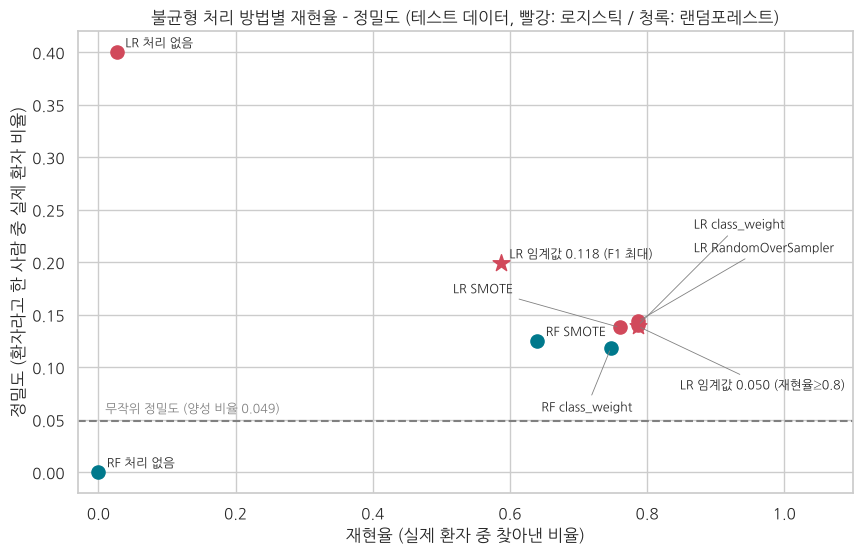

In [9]:
# 재현율 vs 정밀도 - 각 방법이 어디에 위치하는가
plot_df = result.drop(index='기준선(Dummy)')
# 점이 몰려 있는 곳은 라벨 위치를 따로 지정 (단위: 포인트)
offsets = {'LR class_weight': (40, 70), 'LR RandomOverSampler': (40, 50),
           'LR SMOTE': (-120, 25), 'RF class_weight': (-50, -45), f'LR 임계값 {th_recall:.3f} (재현율≥0.8)': (30, -45)}
fig, ax = plt.subplots(figsize=(10, 6))
for name, r in plot_df.iterrows():
    color = '#d1495b' if name.startswith('LR') else '#00798c'
    marker = 'o' if '임계값' not in name else '*'
    ax.scatter(r['재현율'], r['정밀도'], s=160 if marker == '*' else 90, color=color, marker=marker)
    dx, dy = offsets.get(name, (6, 4))
    ax.annotate(name, (r['재현율'], r['정밀도']), xytext=(dx, dy), textcoords='offset points', fontsize=9,
                arrowprops=dict(arrowstyle='-', color='gray', lw=0.6) if name in offsets else None)
ax.axhline(y_test.mean(), color='gray', ls='--')
ax.text(0.01, y_test.mean() + 0.008, f'무작위 정밀도 (양성 비율 {y_test.mean():.3f})', color='gray', fontsize=9)
ax.set_xlim(-0.03, 1.1)
ax.set_xlabel('재현율 (실제 환자 중 찾아낸 비율)')
ax.set_ylabel('정밀도 (환자라고 한 사람 중 실제 환자 비율)')
ax.set_title('불균형 처리 방법별 재현율 - 정밀도 (테스트 데이터, 빨강: 로지스틱 / 청록: 랜덤포레스트)')
plt.show()

* 한줄 확인 : 불균형 처리를 한 방법들은 대부분 **재현율 0.75 ~ 0.79, 정밀도 0.12 ~ 0.14** 부근에 모여 있다.
   * "처리 없음"은 왼쪽(재현율 0 근처)에 있어 환자를 거의 찾지 못한다.
   * 어떤 방법도 "재현율과 정밀도를 동시에 크게" 올리지는 못한다 → 결국 **얼마나 놓치지 않을지 vs 헛경보를 얼마나 감수할지**를 정하는 문제

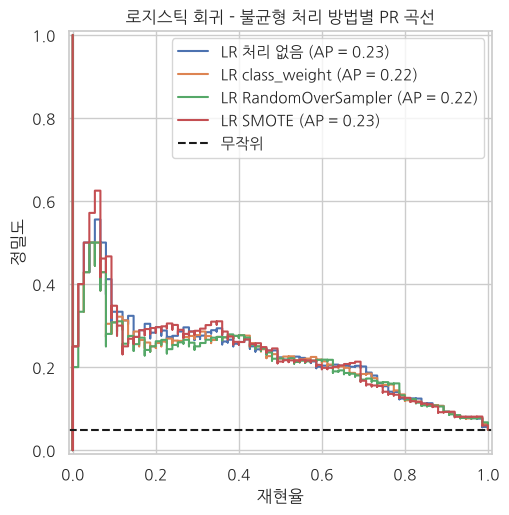

In [10]:
# 로지스틱 회귀 4가지 방법의 PR 곡선 비교
fig, ax = plt.subplots(figsize=(8, 5.5))
for name in ['LR 처리 없음', 'LR class_weight', 'LR RandomOverSampler', 'LR SMOTE']:
    PrecisionRecallDisplay.from_estimator(models[name], X_test, y_test, ax=ax, name=name)
ax.axhline(y_test.mean(), color='k', ls='--', label='무작위')
ax.set_xlabel('재현율')
ax.set_ylabel('정밀도')
ax.set_title('로지스틱 회귀 - 불균형 처리 방법별 PR 곡선')
ax.legend(loc='upper right')
plt.show()

* 한줄 확인 : 네 방법의 PR 곡선이 거의 겹치고 AP도 0.22 ~ 0.23으로 비슷하다.
   * 곡선(모델의 능력)은 같고, 각 방법은 곡선 위의 **다른 지점(임계값)**을 고른 것에 가깝다.

### 3. 오버샘플링의 함정 - 데이터 누수
 * **잘못된 방법** : 학습 데이터 전체에 SMOTE를 먼저 적용 → 그 결과로 교차검증
   * 검증 폴드 안에 **SMOTE로 만든 가짜 행**과, 그 가짜 행을 만들 때 쓴 원래 행이 학습 폴드에 섞여 들어간다 → 거의 "답을 보고 푸는" 상태
 * **올바른 방법** : `ImbPipeline`에 SMOTE를 넣고 교차검증 → 각 폴드의 **학습 부분에만** SMOTE가 적용되고, 검증 부분은 원래 데이터 그대로
 * 같은 랜덤포레스트 + SMOTE로 두 방법을 비교한다(학습 데이터 안에서 5-fold 교차검증).

In [11]:
scoring = ['recall', 'precision', 'roc_auc']

# (X) 잘못된 방법 : 먼저 전처리 + SMOTE를 학습 데이터 전체에 적용한 뒤 교차검증
X_tr_p = preprocess.fit_transform(X_train)
X_res, y_res = SMOTE(random_state=42).fit_resample(X_tr_p, y_train)
wrong = cross_validate(RF(), X_res, y_res, cv=cv, scoring=scoring)

# (O) 올바른 방법 : 파이프라인 안에서 SMOTE (각 폴드의 학습 부분에만 적용)
right = cross_validate(models['RF SMOTE'], X_train, y_train, cv=cv, scoring=scoring)

leak = pd.DataFrame({
    '(X) SMOTE 먼저 → 교차검증': [wrong[f'test_{s}'].mean() for s in scoring],
    '(O) Pipeline 안에서 SMOTE': [right[f'test_{s}'].mean() for s in scoring],
    '테스트 데이터 결과(RF SMOTE)': [result.loc['RF SMOTE', c] for c in ['재현율', '정밀도', 'ROC-AUC']],
}, index=['재현율', '정밀도', 'ROC-AUC']).round(3)
print('SMOTE 후 학습 데이터 크기 :', X_res.shape, '/ 뇌졸중 비율', y_res.mean())
leak

SMOTE 후 학습 데이터 크기 : (6804, 21) / 뇌졸중 비율 0.5


,(X) SMOTE 먼저 → 교차검증,(O) Pipeline 안에서 SMOTE,테스트 데이터 결과(RF SMOTE)
재현율,0.953,0.644,0.640
정밀도,0.798,0.130,0.125
ROC-AUC,0.962,0.812,0.809


* 한줄 확인 : SMOTE를 먼저 적용하고 교차검증하면 재현율 **0.953**, 정밀도 **0.798**, ROC-AUC **0.962**로 매우 좋아 보인다.
   * 올바른 방법(Pipeline)의 교차검증은 재현율 0.644, 정밀도 0.130, ROC-AUC 0.812이고, 이는 실제 테스트 결과(0.640 / 0.125 / 0.809)와 거의 일치한다.
   * 잘못된 방법은 검증 폴드에 SMOTE로 만든 **가짜 뇌졸중 행**(학습 폴드의 진짜 행 사이에서 만든 것)이 들어가 쉽게 맞힌 것 → **누수(leakage)로 부풀려진 점수**
 * 오버샘플링·스케일링·결측 대체처럼 데이터를 보고 무언가를 계산하는 단계는 **항상 Pipeline 안에** 넣고, 분할 후 학습 데이터에서만 `fit` 한다.

### 4. 위험 요인 EDA - 무엇이 뇌졸중 비율을 높이나?
 * 그룹별 **뇌졸중 비율**과 함께 **환자 수 / 뇌졸중 수**를 항상 같이 본다.
   * 전체 비율이 4.9%이므로 100명짜리 그룹이면 뇌졸중은 5명 안팎 → 1~2명 차이로 비율이 크게 흔들린다.
 * 전체 데이터(5,109명)를 사용한다(모델 평가와 무관한 탐색).

In [12]:
def rate_table(df, col):
    """그룹별 환자 수, 뇌졸중 수, 뇌졸중 비율(%), 평균 나이"""
    g = df.groupby(col, observed=True)
    return pd.DataFrame({'환자수': g['stroke'].size(),
                         '뇌졸중 수': g['stroke'].sum(),
                         '뇌졸중 비율(%)': (g['stroke'].mean() * 100).round(1),
                         '평균 나이': g['age'].mean().round(1)})

eda = dat.copy()
eda['연령대'] = pd.cut(eda['age'], bins=[0, 20, 40, 50, 60, 70, 80, 100], right=False,
                    labels=['0-19', '20-39', '40-49', '50-59', '60-69', '70-79', '80+'])
eda['평균 혈당 구간'] = pd.cut(eda['avg_glucose_level'], bins=[0, 100, 140, 200, 300], right=False,
                         labels=['<100', '100-139', '140-199', '200+'])
eda['BMI 구간'] = pd.cut(eda['bmi'], bins=[0, 18.5, 25, 30, 100], right=False,
                       labels=['저체중(<18.5)', '정상(18.5-25)', '과체중(25-30)', '비만(30+)'])
eda['BMI 구간'] = eda['BMI 구간'].cat.add_categories('결측').fillna('결측')
eda['고혈압'] = eda['hypertension'].map({0: '없음', 1: '있음'})
eda['심장병'] = eda['heart_disease'].map({0: '없음', 1: '있음'})
eda['흡연'] = pd.Categorical(eda['smoking_status'].map(
    {'never smoked': '비흡연', 'formerly smoked': '과거 흡연', 'smokes': '현재 흡연', 'Unknown': '모름'}),
    categories=['비흡연', '과거 흡연', '현재 흡연', '모름'])

factors = ['연령대', '평균 혈당 구간', '고혈압', '심장병', 'BMI 구간', '흡연']

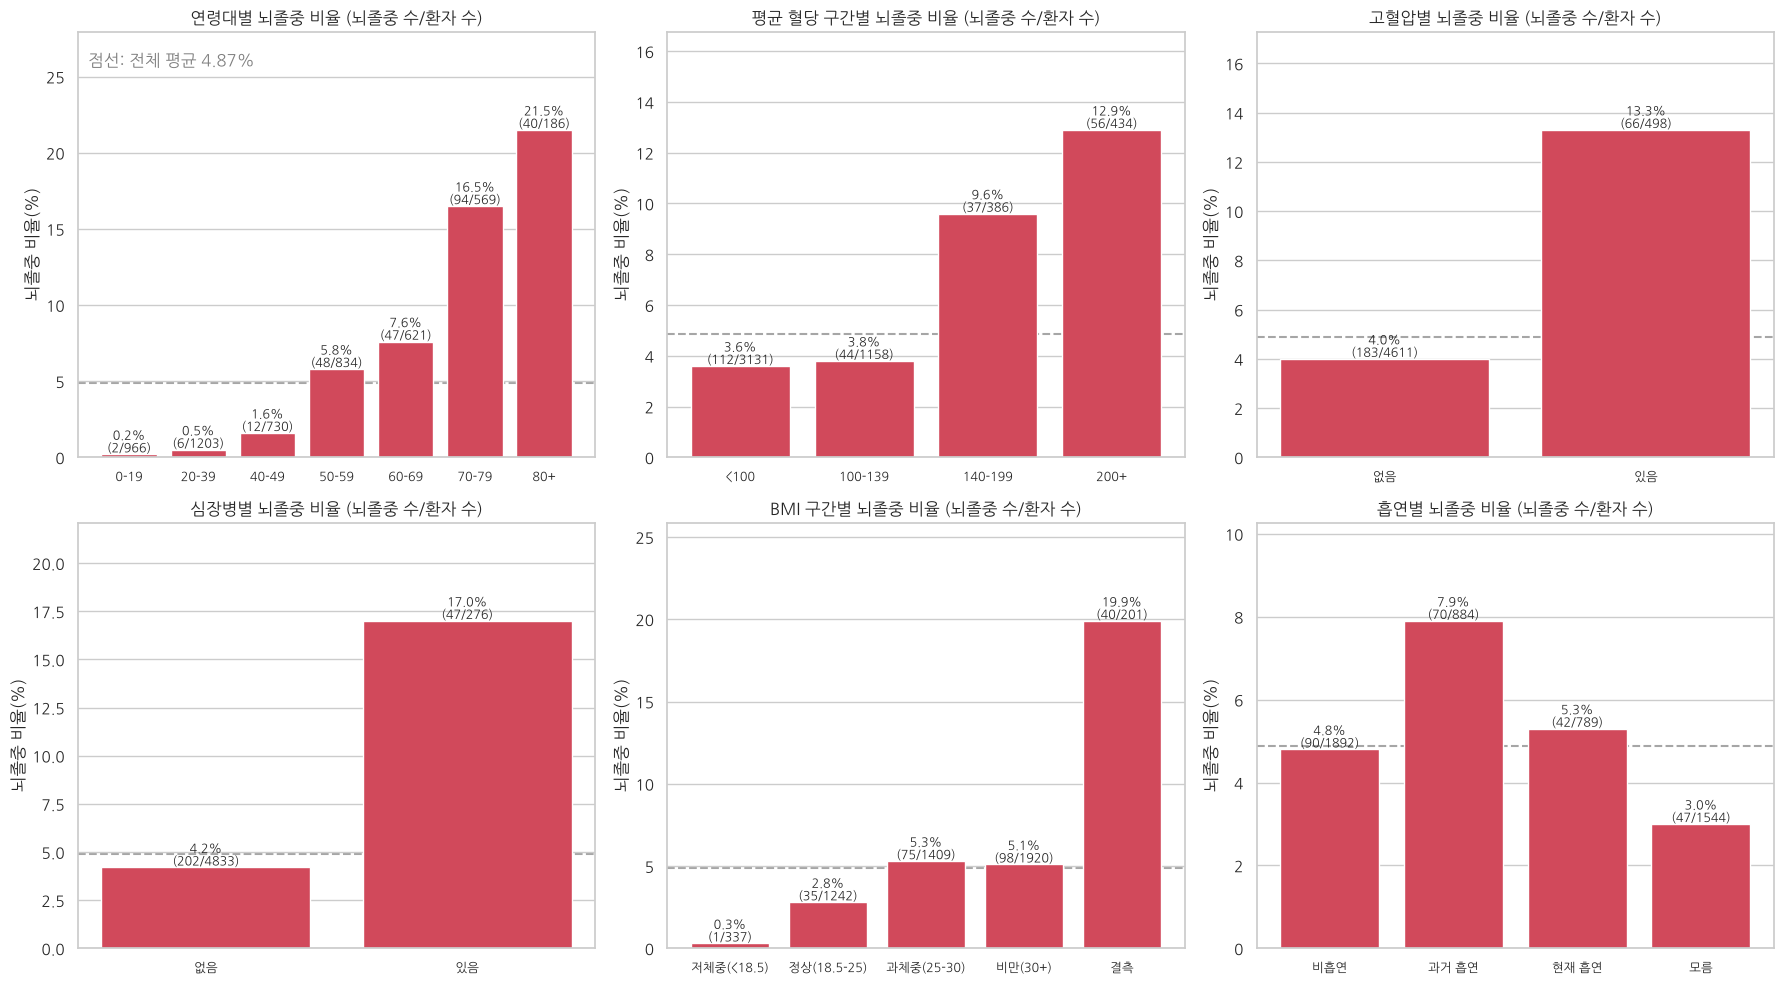

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
overall = eda['stroke'].mean() * 100
for ax, col in zip(axes.ravel(), factors):
    t = rate_table(eda, col)
    bars = ax.bar(t.index.astype(str), t['뇌졸중 비율(%)'], color='#d1495b')
    ax.bar_label(bars, labels=[f"{r:.1f}%\n({s}/{n})" for r, s, n in
                               zip(t['뇌졸중 비율(%)'], t['뇌졸중 수'], t['환자수'])], fontsize=9)
    ax.axhline(overall, color='gray', ls='--', alpha=0.7, zorder=0)
    ax.set_title(f'{col}별 뇌졸중 비율 (뇌졸중 수/환자 수)')
    ax.set_ylim(0, t['뇌졸중 비율(%)'].max() * 1.3)
    ax.set_ylabel('뇌졸중 비율(%)')
    ax.tick_params(axis='x', labelsize=9)
    ax.grid(axis='x', visible=False)
axes[0, 0].text(0.02, 0.92, f'점선: 전체 평균 {overall:.2f}%', transform=axes[0, 0].transAxes, color='gray')
plt.tight_layout()
plt.show()

#### 4-1. 연령대

In [14]:
rate_table(eda, '연령대')

,환자수,뇌졸중 수,뇌졸중 비율(%),평균 나이
연령대,,,,
0-19,966,2,0.2,9.7
20-39,1203,6,0.5,30.0
40-49,730,12,1.6,44.5
50-59,834,48,5.8,54.4
60-69,621,47,7.6,64.1
70-79,569,94,16.5,75.1
80+,186,40,21.5,80.9


* 한줄 확인 : 나이가 가장 강한 위험 요인이다. 0-19세 **0.2%**(2/966) → 50대 5.8% → 70대 **16.5%**(94/569) → 80세 이상 **21.5%**(40/186)
   * 50대부터 전체 평균(4.87%)을 넘고, 60대(7.6%) → 70대(16.5%)에서 2배 이상 뛴다.
   * 49세 이하는 2,899명 중 뇌졸중 20명뿐 → 젊은 층은 표본이 많아도 사건 수가 적다.

#### 4-2. 평균 혈당

In [15]:
rate_table(eda, '평균 혈당 구간')

,환자수,뇌졸중 수,뇌졸중 비율(%),평균 나이
평균 혈당 구간,,,,
<100,3131,112,3.6,41.3
100-139,1158,44,3.8,39.5
140-199,386,37,9.6,49.4
200+,434,56,12.9,61.6


* 한줄 확인 : 평균 혈당 140 미만은 3.6 ~ 3.8%로 비슷하고, **140-199는 9.6%, 200 이상은 12.9%**(56/434)로 높다.
   * 단, 200 이상 그룹의 평균 나이는 61.6세(140 미만은 약 40세)로, 나이의 영향이 섞여 있다.
   * `avg_glucose_level`은 공복 혈당이 아니라 "평균 혈당"이므로 구간은 비교용 참고 기준이다.

#### 4-3. 고혈압 / 심장병

In [16]:
pd.concat({'고혈압': rate_table(eda, '고혈압'), '심장병': rate_table(eda, '심장병')})

환자수  뇌졸중 수  뇌졸중 비율(%)  평균 나이
    고혈압                               
고혈압 없음   4611    183        4.0   41.2
    있음    498     66       13.3   62.2
심장병 없음   4833    202        4.2   41.8
    있음    276     47       17.0   68.2

* 한줄 확인 : 고혈압이 있으면 **13.3%**(66/498) vs 없으면 4.0%, 심장병이 있으면 **17.0%**(47/276) vs 없으면 4.2%
   * 하지만 고혈압·심장병 환자의 평균 나이는 62.2세 / 68.2세로, 없는 사람(약 41세)보다 20세 이상 많다. → 나이를 맞추고 다시 본다.

#### 4-4. 나이를 고정하고 다시 보기 - 고혈압·심장병은 나이 때문일까?
 * 고혈압·심장병 환자는 평균 나이가 높다. 비율 차이가 **나이 때문인지** 확인하려면 같은 연령대끼리 비교한다.

In [17]:
eda['연령그룹'] = pd.cut(eda['age'], bins=[0, 45, 65, 100], right=False, labels=['45세 미만', '45-64세', '65세 이상'])
pd.concat({'고혈압': eda.groupby(['연령그룹', '고혈압'], observed=True)['stroke'].agg(['size', 'sum', 'mean']),
           '심장병': eda.groupby(['연령그룹', '심장병'], observed=True)['stroke'].agg(['size', 'sum', 'mean'])}
         ).rename(columns={'size': '환자수', 'sum': '뇌졸중 수', 'mean': '뇌졸중 비율'}).round(3)

환자수  뇌졸중 수  뇌졸중 비율
    연령그룹   고혈압                     
고혈압 45세 미만 없음   2476      9   0.004
           있음     56      1   0.018
    45-64세 없음   1338     65   0.049
           있음    212     15   0.071
    65세 이상 없음    797    109   0.137
           있음    230     50   0.217
심장병 45세 미만 없음   2525     10   0.004
           있음      7      0   0.000
    45-64세 없음   1461     67   0.046
           있음     89     13   0.146
    65세 이상 없음    847    125   0.148
           있음    180     34   0.189

* 한줄 확인 : 같은 연령그룹 안에서 비교하면 차이는 **줄어들지만 남아 있다.**
   * 고혈압 : 45-64세 7.1% vs 4.9%, 65세 이상 **21.7% vs 13.7%**
   * 심장병 : 45-64세 **14.6%**(13/89) vs 4.6%, 65세 이상 18.9% vs 14.8%
   * 45세 미만은 고혈압 있음 56명 중 1명, 심장병 있음 7명 중 0명으로 **표본이 너무 적어** 판단하기 어렵다.
 * 전체 비교(13.3% vs 4.0%)에서 보인 3배 이상의 차이 중 상당 부분은 나이 때문이지만, 나이와 별개로도 위험을 높이는 요인으로 보인다(관찰 데이터이므로 인과 관계는 아님).

#### 4-5. BMI (결측 포함)

In [18]:
rate_table(eda, 'BMI 구간')

,환자수,뇌졸중 수,뇌졸중 비율(%),평균 나이
BMI 구간,,,,
저체중(<18.5),337,1,0.3,10.9
정상(18.5-25),1242,35,2.8,33.8
과체중(25-30),1409,75,5.3,49.1
비만(30+),1920,98,5.1,49.8
결측,201,40,19.9,52.0


* 한줄 확인 : 저체중 0.3%(1/337), 정상 2.8%, 과체중 5.3%, 비만 5.1%, **결측 19.9%**(40/201)
   * 저체중 그룹의 평균 나이는 10.9세(대부분 어린이), 정상 33.8세, 과체중·비만은 약 49세 → BMI 구간 차이도 **나이 차이**가 크게 섞여 있다.
   * 과체중과 비만의 비율은 거의 같다(5.3% vs 5.1%) → 이 데이터에서 BMI 자체의 영향은 뚜렷하지 않다.
   * 가장 높은 그룹은 오히려 **결측**이다. 1-2에서 결측 행을 지우지 않고 결측 여부를 변수로 남긴 이유

#### 4-6. 흡연

In [19]:
rate_table(eda, '흡연')

,환자수,뇌졸중 수,뇌졸중 비율(%),평균 나이
흡연,,,,
비흡연,1892,90,4.8,46.7
과거 흡연,884,70,7.9,55.0
현재 흡연,789,42,5.3,47.1
모름,1544,47,3.0,30.2


In [20]:
# '모름'에는 어린이가 많다 - 성인(18세 이상)만 다시 보기
rate_table(eda[eda['age'] >= 18], '흡연')

,환자수,뇌졸중 수,뇌졸중 비율(%),평균 나이
흡연,,,,
비흡연,1752,90,5.1,49.3
과거 흡연,859,70,8.1,56.2
현재 흡연,780,42,5.4,47.5
모름,862,45,5.2,48.5


* 한줄 확인 : 전체로 보면 과거 흡연 **7.9%**, 현재 흡연 5.3%, 비흡연 4.8%, 모름 **3.0%**
   * '모름'의 평균 나이는 30.2세로 가장 낮다 → 어린이가 많아서 비율이 낮게 나온 것
   * 성인(18세 이상)만 보면 '모름'은 1,544명 → 862명으로 줄고 비율은 5.2%로 비흡연(5.1%)과 비슷해진다.
 * 과거 흡연(성인 8.1%)이 가장 높지만 평균 나이도 56.2세로 가장 많다. 현재 흡연(5.4%)과 비흡연(5.1%)은 큰 차이가 없다.
   * 이 데이터만으로 "흡연이 뇌졸중 위험을 높인다/안 높인다"를 결론 내리기는 어렵다. 흡연 정보의 30%가 '모름'이라는 한계도 있다.

### 5. 정리
| 질문 | 기본 분석 (원본 / 1편) | 추가 분석 결과 (2편) |
|---|---|---|
| 불균형을 처리하면 환자를 찾을 수 있나? | 원본 정확도 95%, 1편 재현율 0.000 (임계값 0.5) | LR + class_weight / 오버샘플링으로 재현율 **0.760 ~ 0.787** (75명 중 57 ~ 59명), 정밀도 0.14 안팎 |
| 어떤 방법이 가장 좋은가? | - | LR 계열의 ROC-AUC는 모두 0.842 ~ 0.844로 같다. **임계값 0.050**만 바꿔도 class_weight와 같은 재현율 0.787. F1 최고는 임계값 0.118(F1 0.297) |
| 랜덤포레스트는? | 정확도 95.04% | 처리 없음 재현율 0.000. class_weight 0.747, SMOTE 0.640, ROC-AUC는 0.81 수준으로 LR보다 낮음 |
| 오버샘플링을 먼저 하면? | - | 교차검증 재현율 **0.953**으로 부풀려짐. Pipeline 안에서 하면 0.644 (테스트 0.640과 일치) |
| bmi 결측은? | 사용하지 않음 | 결측 201명의 뇌졸중 비율 **19.9%** (있음 4.3%) → 삭제 대신 중앙값 대체 + 결측 표시 열 |
| 가장 강한 위험 요인은? | - | **나이** : 0-19세 0.2% → 80세 이상 21.5% |
| 고혈압·심장병·혈당은? | - | 고혈압 13.3%, 심장병 17.0%, 혈당 200+ 12.9%. 나이를 맞춰도 고혈압(65세 이상 21.7% vs 13.7%)·심장병 차이는 남는다 |
| BMI·흡연은? | - | 차이의 대부분이 나이로 설명됨. 과체중 5.3% ≈ 비만 5.1%, 성인만 보면 흡연 '모름' 5.2% ≈ 비흡연 5.1% |

#### 배운 점
 * 불균형 처리(가중치, 오버샘플링)는 **정확도를 낮추는 대신 재현율을 높인다.** 목적(환자를 놓치지 않기)에 맞는 지표로 판단해야 한다.
 * 로지스틱 회귀에서는 class_weight·오버샘플링·임계값 조정이 비슷한 결과를 낸다. 먼저 **가장 단순한 임계값 조정**부터 시도해 볼 만하다.
 * 임계값은 테스트 데이터가 아니라 **학습 데이터의 교차검증**으로 정한다.
 * 오버샘플링은 반드시 **분할 후 학습 데이터에만**, `imblearn.pipeline.Pipeline` 안에서 적용한다. 그렇지 않으면 점수가 크게 부풀려진다.
 * 테스트 데이터의 뇌졸중 환자는 **75명**뿐이다. 방법 간 재현율 차이 1~2명(0.01~0.03)은 분할에 따른 우연일 수 있으므로, 비슷한 결과는 "비슷하다"고 해석한다.
 * 그룹별 비율은 **표본 수**와 **나이 같은 혼재 변수**를 함께 확인해야 오해하지 않는다. 결측도 정보가 될 수 있다.

#### 다음에 해 볼 분석
 * 로지스틱 회귀 계수(오즈비)로 나이를 통제한 각 위험 요인의 효과 크기 확인
 * 확률 보정(calibration) 곡선 - "위험도 10%"라는 예측이 실제로 10%인지 확인
 * 오경보 1건과 놓친 환자 1건의 **비용**을 정해 비용 기준으로 임계값 고르기